# Assignment 13: Random Forest vs XGBoost - Predicting Online Purchases

In this assignment, I will compare two ensemble models, Random Forest and XGBoost, to predict whether a visitor to an online store will make a purchase. I used the Online Shoppers Purchasing Intention dataset (12,330 Google Analytics sessions) instead of the Breast Cancer dataset (with my instructor's permission). The Breast Cancer data is very easy to classify (my SVM model reached 98% accuracy in an earlier assignment), so both models would score almost the same, and the effect of tuning would be hard to see. The Online Shoppers data is larger, harder, and imbalanced (only 15.6% of sessions end in a purchase), which makes it better for comparing models and hyperparameter tuning.

I used exactly the same data split and preparation as my logistic regression assignment, so I can also compare both ensemble models with logistic regression in the final report.

My steps:
- Load, clean, split, and explore the data
- Train and evaluate a Random Forest model
- Train and evaluate an XGBoost model
- Compare both models using accuracy, precision, recall, F1-score, and ROC-AUC
- Tune the hyperparameters of both models with RandomizedSearchCV
- Compare the final models, including logistic regression, and recommend the best one

## Step 1: Load, Split, Explore, and Prepare the Data

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay)


In [2]:
pd.set_option("display.max_columns", None)

In [3]:
shop = pd.read_csv("online_shoppers_intention.csv")
print("Shape:", shop.shape)
display(shop.head())

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
print("\nData types:")
print(shop.dtypes)


Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object


In [5]:
print("\nUnique values per column:")
print(shop.nunique())


Unique values per column:
Administrative               27
Administrative_Duration    3335
Informational                17
Informational_Duration     1258
ProductRelated              311
ProductRelated_Duration    9551
BounceRates                1872
ExitRates                  4777
PageValues                 2704
SpecialDay                    6
Month                        10
OperatingSystems              8
Browser                      13
Region                        9
TrafficType                  20
VisitorType                   3
Weekend                       2
Revenue                       2
dtype: int64


In [6]:
print("\nMissing values:", shop.isnull().sum().sum())
print("Duplicate rows:", shop.duplicated().sum())


Missing values: 0
Duplicate rows: 125


In [7]:
print("\nTarget (Revenue):")
print(shop["Revenue"].value_counts())
print((shop["Revenue"].value_counts(normalize=True) * 100).round(1))


Target (Revenue):
Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.5
True     15.5
Name: proportion, dtype: float64


Interpretation
The dataset has 12,330 website sessions and 18 columns. Each row is one visit to an online store, recorded with Google Analytics. The target is Revenue: True means the visit ended in a purchase.

What the columns represent:

Page activity: Administrative (account pages), Informational (pages like "about us" or shipping information), and ProductRelated (product pages), each with the number of pages visited and the total time spent on them in seconds.
Google Analytics metrics: BounceRates (how often visitors leave after viewing only one page), ExitRates (how often a page is the last one viewed), and PageValues (the average value of the pages visited, based on how often they come before a purchase).
Timing: SpecialDay (how close the visit was to a holiday such as Valentine's Day), Month, and Weekend.
Visitor information: VisitorType (new or returning), and OperatingSystems, Browser, Region, and TrafficType.
Data types:

Month and VisitorType are text, and Weekend and Revenue are True/False, so they will need to be converted into numbers.
OperatingSystems, Browser, Region, and TrafficType are stored as numbers, but they are actually category codes. The real names were replaced with numbers, so a higher number does not mean "more". I will treat them as categories, not as amounts.
Month has only 10 unique values, because January and April are not in the data.
Structure checks:

There are no missing values.
There are 125 duplicate rows, which I will remove before splitting, so the same session cannot appear in both the training and test sets.
Target:

10,422 sessions (84.5%) did not end in a purchase, and only 1,908 (15.5%) did.
The classes are imbalanced. A model that always predicted "no purchase" would already be 84.5% accurate while never finding a single buyer, so accuracy alone will not be a good measure. I will focus on precision, recall, F1-score, and ROC-AUC.

## Step 2: Remove Duplicates and Split the Data

In [8]:
shop = shop.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", shop.shape)

X = shop.drop(columns="Revenue")
y = shop["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Buyers in train (%):", round(y_train.mean() * 100, 1), "| in test (%):", round(y_test.mean() * 100, 1))

Shape after removing duplicates: (12205, 18)
X_train: (9764, 17) | X_test: (2441, 17)
Buyers in train (%): 15.6 | in test (%): 15.6


Interpretation
I removed the 125 duplicate rows, leaving 12,205 sessions. I converted the target (Revenue) from True/False into 1/0, and separated the 17 features from the target.

I split the data into 80% training (9,764 sessions) and 20% testing (2,441 sessions), using stratify. Both sets have exactly 15.6% buyers, so the test set fairly represents the imbalance in the data. From now on, I explore and prepare the data using only the training set.

## Step 3: Exploratory Data Analysis (Training Data)

In [9]:
train = X_train.copy()
train["Revenue"] = y_train

display(train.describe().round(2))
display(train[["Month", "VisitorType", "Weekend"]].describe())

num_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]
print("Skewness:")
print(train[num_cols].skew().round(2).sort_values(ascending=False))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Revenue
count,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00
mean,2.34,82.22,0.51,34.95,32.10,1207.26,0.02,0.04,5.95,0.06,2.13,2.37,3.13,4.06,0.16
std,3.35,179.50,1.28,143.83,44.82,1926.39,0.05,0.05,18.86,0.20,0.91,1.73,2.39,4.03,0.36
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,0.00
25%,0.00,0.00,0.00,0.00,8.00,193.47,0.00,0.01,0.00,0.00,2.00,2.00,1.00,2.00,0.00
50%,1.00,9.00,0.00,0.00,18.00,617.00,0.00,0.02,0.00,0.00,2.00,2.00,3.00,2.00,0.00
75%,4.00,94.72,0.00,0.00,39.00,1483.65,0.02,0.05,0.00,0.00,3.00,2.00,4.00,4.00,0.00
max,27.00,3398.75,24.00,2549.38,705.00,63973.52,0.20,0.20,361.76,1.00,8.00,13.00,9.00,20.00,1.00


,Month,VisitorType,Weekend
count,9764,9764,9764
unique,10,3,2
top,May,Returning_Visitor,False
freq,2674,8347,7480


Skewness:
ProductRelated_Duration    7.87
Informational_Duration     7.54
PageValues                 6.55
Administrative_Duration    5.68
ProductRelated             4.39
Informational              4.10
BounceRates                3.17
ExitRates                  2.24
Administrative             1.99
dtype: float64


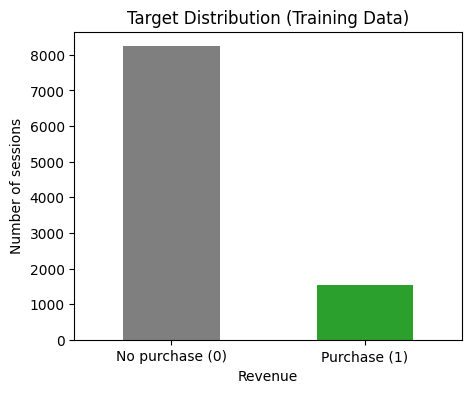

In [10]:
ax = train["Revenue"].value_counts().plot(kind="bar", color=["tab:gray", "tab:green"], figsize=(5, 4))
ax.set_xticklabels(["No purchase (0)", "Purchase (1)"], rotation=0)
ax.set_title("Target Distribution (Training Data)"); ax.set_ylabel("Number of sessions")
plt.show()

Interpretation: Summary Statistics and Target Distribution
Target: in the training data, about 8,250 sessions did not end in a purchase and about 1,500 did (15.6%). The bar chart shows how much smaller the purchase class is.

Numeric features:

A typical session views 18 product pages (median) and spends about 617 seconds (about 10 minutes) on them. Most visitors view few account (median 1) or information pages (median 0).
PageValues has a median of 0, and at least 75% of sessions have a value of 0, meaning most visitors never view pages that usually come before a purchase. The maximum is 361.76.
BounceRates and ExitRates are small decimals (averages of 0.02 and 0.04).
All count and duration features are strongly right-skewed, with skewness between 2 and 7.9. For example, ProductRelated_Duration has a median of 617 seconds but a maximum of almost 64,000 seconds (about 17.8 hours). A few sessions with extreme values stretch the scale, so I will apply a log transformation before modelling.
Categorical features:

May is the most common month (2,674 sessions), most visitors are returning visitors (8,347 of 9,764), and most visits happen on weekdays (7,480).
OperatingSystems, Browser, Region, and TrafficType appear as numbers in the statistics table, but their means and standard deviations have no meaning, because they are category codes.

In [11]:
for col in ["Month", "VisitorType", "Weekend", "SpecialDay", "TrafficType"]:
    rate = train.groupby(col)["Revenue"].agg(sessions="count", conversion_rate="mean")
    rate["conversion_rate"] = (rate["conversion_rate"] * 100).round(1)
    print(f"\n=== Conversion rate (%) by {col} ===")
    print(rate.sort_values("conversion_rate", ascending=False).to_string())


=== Conversion rate (%) by Month ===
       sessions  conversion_rate
Month                           
Nov        2358             25.4
Oct         433             22.4
Sep         354             18.9
Aug         360             17.2
Jul         353             14.4
Dec        1363             13.1
May        2674             10.7
Mar        1500             10.6
June        225             10.2
Feb         144              2.1

=== Conversion rate (%) by VisitorType ===
                   sessions  conversion_rate
VisitorType                                 
New_Visitor            1349             24.1
Other                    68             23.5
Returning_Visitor      8347             14.2

=== Conversion rate (%) by Weekend ===
         sessions  conversion_rate
Weekend                           
True         2284             17.5
False        7480             15.1

=== Conversion rate (%) by SpecialDay ===
            sessions  conversion_rate
SpecialDay                          

Interpretation: Conversion Rate by Group
The conversion rate is the percentage of sessions that ended in a purchase.

Month:

November has the highest conversion rate (25.4%), followed by October (22.4%) and September (18.9%), likely because of holiday shopping and sales like Black Friday.
February has the lowest conversion rate (2.1%).
May has the most sessions (2,674) but a low conversion rate (10.7%), so it brings a lot of traffic but relatively few buyers.
Visitor type:

New visitors convert at 24.1%, much higher than returning visitors (14.2%). This is surprising. Returning visitors may often come back just to browse, compare prices, or check their account. The "Other" group has only 68 sessions, so its rate is less reliable.
Weekend:

Weekend sessions convert slightly better (17.5%) than weekday sessions (15.1%).
Special day:

Sessions close to a special day convert much less (3.5% to 8.8%) than sessions on normal days (16.7%). This may be because special days in this data fall around Valentine's Day (February) and Mother's Day (May), which are low-converting months. Visitors may also browse for gift ideas before buying elsewhere.
Traffic type:

Traffic type 2 is the largest high-performing source (3,111 sessions, 21.5% conversion). Types 1 and 3 bring a lot of traffic but convert at only about 9% to 11%, and type 13 converts at only 6%.
Several traffic types have very few sessions (for example, types 15 to 19 have between 1 and 31 sessions). Their conversion rates (such as 0% or 34.4%) are not reliable, so I will group rare traffic types into one "Other" category before encoding.

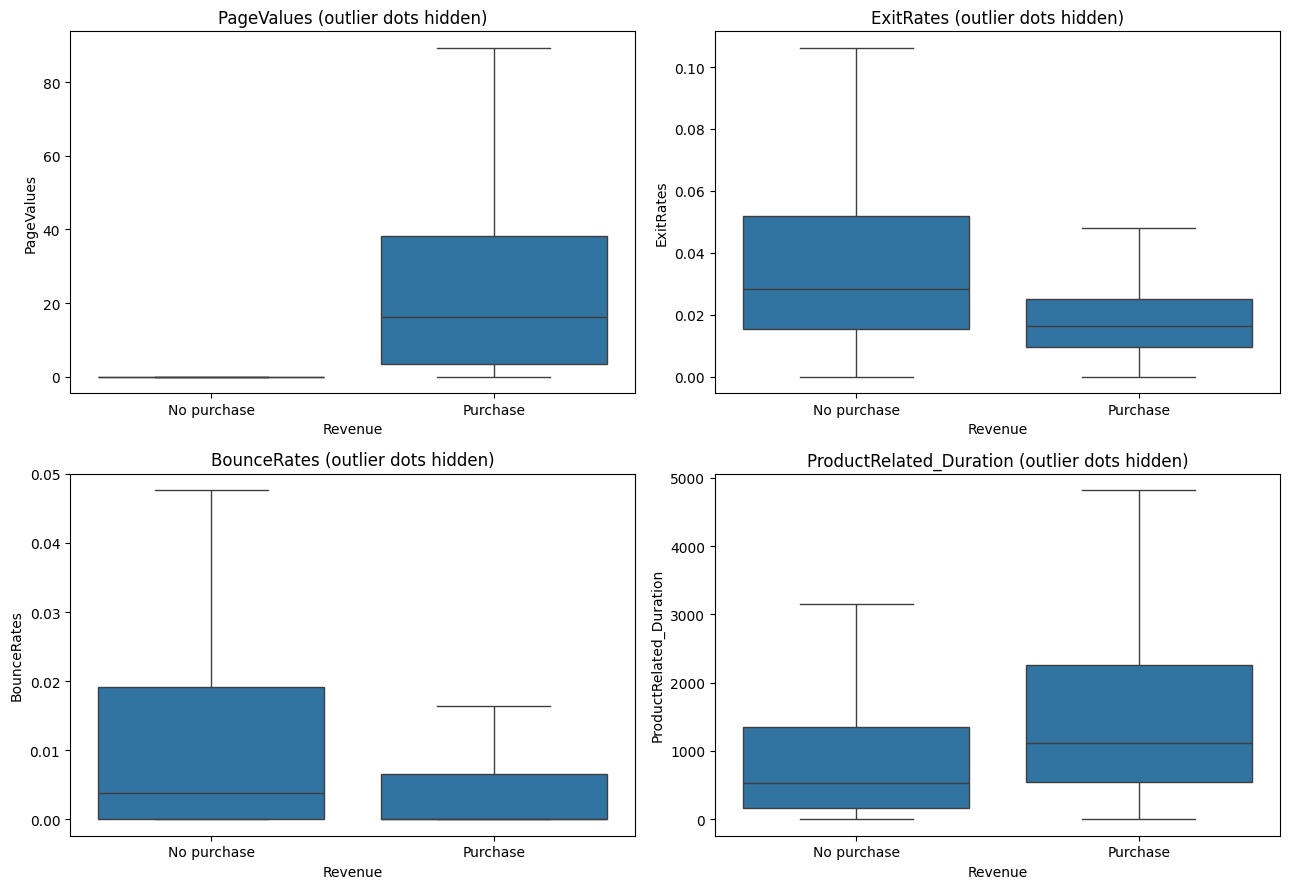

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration"]):
    sns.boxplot(data=train, x="Revenue", y=col, ax=ax, showfliers=False)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No purchase", "Purchase"])
    ax.set_title(f"{col} (outlier dots hidden)")
plt.tight_layout(); plt.show()



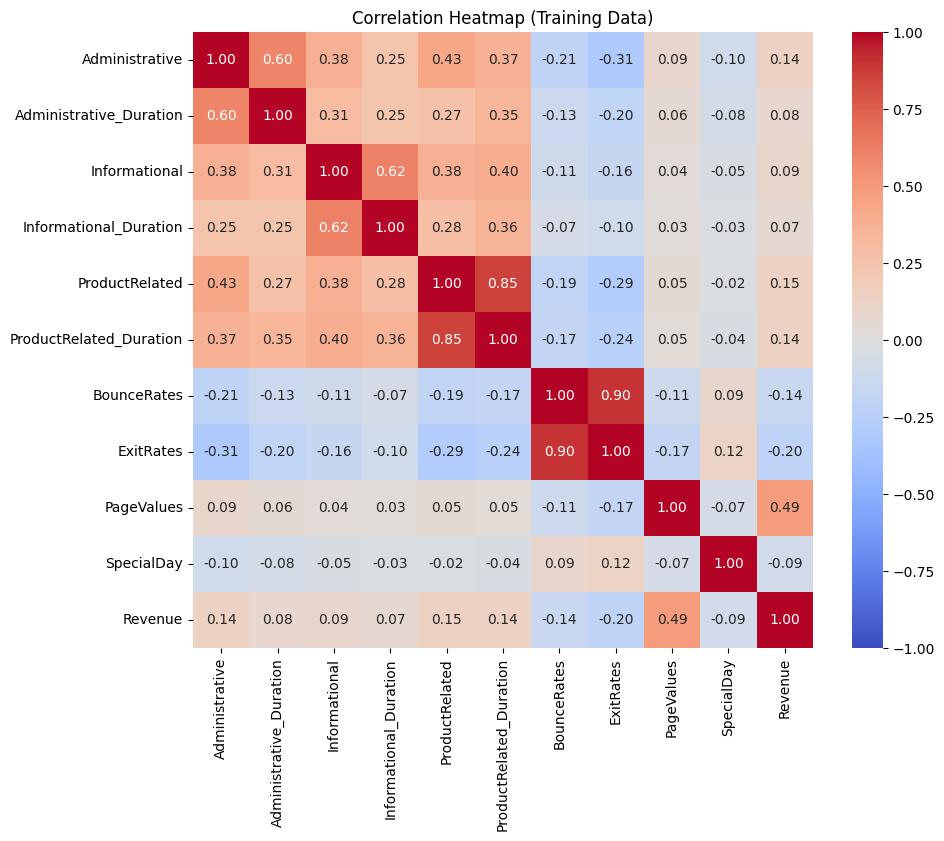

In [14]:
plt.figure(figsize=(10, 8))
sns.heatmap(train[num_cols + ["SpecialDay", "Revenue"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap (Training Data)")
plt.show()

Interpretation: Buyers vs Non-Buyers and Correlations
Boxplots (outlier dots hidden to show typical sessions):

PageValues shows the biggest difference. Almost all non-buyers have a PageValue of 0, while buyers have a median of about 16, with the middle half between about 4 and 38. Buyers view pages that usually lead to purchases, such as product and checkout pages.
ExitRates and BounceRates are lower for buyers. Buyers stay on the site and keep clicking, while non-buyers are more likely to leave quickly.
Buyers spend more time on product pages (median about 1,100 seconds vs about 500 seconds for non-buyers).
Correlation heatmap:

PageValues has by far the strongest relationship with purchase (0.49).
ExitRates (-0.20) and BounceRates (-0.14) have negative relationships: higher exit and bounce rates are linked to fewer purchases.
Page counts and durations have weak positive relationships (0.07 to 0.15).
SpecialDay has a weak negative relationship (-0.09), matching the lower conversion rate near holidays.
Multicollinearity:

BounceRates and ExitRates are very strongly correlated (0.90), so they carry almost the same information.
ProductRelated and ProductRelated_Duration are also strongly correlated (0.85), because viewing more pages takes more time.
Since logistic regression coefficients become unreliable when features overlap this much, I will keep ExitRates (the stronger of the two) and drop BounceRates.
Note: PageValues is calculated by Google Analytics using past purchases, so it is very closely linked to the target. I will keep it, but later compare the model with and without it to see how much the model depends on this one feature.

## Step 4: Data Preparation

In [15]:
print("Missing values - train:", X_train.isnull().sum().sum(), "| test:", X_test.isnull().sum().sum())


Missing values - train: 0 | test: 0


In [16]:
traffic_counts = X_train["TrafficType"].value_counts()
rare_traffic = traffic_counts[traffic_counts < 100].index.tolist()
print("Rare traffic types grouped as 'Other':", sorted(rare_traffic))

Rare traffic types grouped as 'Other': [7, 9, 14, 15, 16, 17, 18, 19]


In [17]:
log_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "ExitRates", "PageValues"]

def prepare(data):
    data = data.copy()
    data = data.drop(columns=["BounceRates", "OperatingSystems", "Browser", "Region"])
    data["TrafficType"] = data["TrafficType"].where(~data["TrafficType"].isin(rare_traffic), "Other").astype(str)
    data["Weekend"] = data["Weekend"].astype(int)
    for col in log_cols:
        data[col] = np.log1p(data[col])
    data = pd.get_dummies(data, columns=["Month", "VisitorType", "TrafficType"], drop_first=True, dtype=int)
    return data

X_train_p = prepare(X_train)
X_test_p = prepare(X_test).reindex(columns=X_train_p.columns, fill_value=0)
print("Shape after preparation - train:", X_train_p.shape, "| test:", X_test_p.shape)

Shape after preparation - train: (9764, 32) | test: (2441, 32)


In [18]:
print("\nSkewness after log (train):")
print(X_train_p[log_cols].skew().round(2).sort_values(ascending=False))
print("\nColumns:", list(X_train_p.columns))


Skewness after log (train):
ExitRates                  2.13
Informational              2.01
Informational_Duration     1.91
PageValues                 1.80
Administrative             0.56
Administrative_Duration    0.24
ProductRelated            -0.04
ProductRelated_Duration   -1.43
dtype: float64

Columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend', 'Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_June', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'TrafficType_10', 'TrafficType_11', 'TrafficType_13', 'TrafficType_2', 'TrafficType_20', 'TrafficType_3', 'TrafficType_4', 'TrafficType_5', 'TrafficType_6', 'TrafficType_8', 'TrafficType_Other']


Interpretation
There are no missing values in either set, so no imputation was needed.

Changes I made (all values learned from the training data, then applied to both sets):

Dropped BounceRates (almost identical to ExitRates, correlation 0.90), and OperatingSystems, Browser, and Region (anonymized technical codes with no clear marketing meaning, which would have added many columns with little value).
Grouped rare traffic types (fewer than 100 training sessions) into one "Other" category, so the model does not learn from groups that are too small to be reliable.
Converted Weekend from True/False to 1/0.
Applied a log transformation (log1p) to the page counts, durations, ExitRates, and PageValues to reduce their strong right skew.
One-hot encoded Month, VisitorType, and TrafficType, with drop_first=True. The baseline categories are August, New_Visitor, and traffic type 1.
Results:

Both sets now have the same 32 numeric features.
The log transformation greatly reduced the skew of most columns. For example, ProductRelated went from 4.39 to -0.04, and Administrative_Duration from 5.68 to 0.24.
ExitRates is still skewed (2.13), because its values are very small decimals (around 0.02 to 0.05), and the log of numbers this close to 1 barely changes them.
The features will be scaled with StandardScaler inside the model Pipeline, because logistic regression's regularization treats all coefficients fairly only when the features are on the same scale.

## Step 5: Train and Evaluate a Random Forest Model

In [19]:
# Helper: evaluate any model the same way
def evaluate(name, model, threshold=0.5):
    train_pred = model.predict(X_train_p)
    prob = model.predict_proba(X_test_p)[:, 1]
    pred = (prob >= threshold).astype(int)
    result = {"Model": name,
              "Train acc": accuracy_score(y_train, train_pred),
              "Test acc": accuracy_score(y_test, pred),
              "Precision": precision_score(y_test, pred),
              "Recall": recall_score(y_test, pred),
              "F1": f1_score(y_test, pred),
              "ROC-AUC": roc_auc_score(y_test, prob)}
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["No purchase", "Purchase"]))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["No purchase", "Purchase"]).plot(cmap="Blues", ax=axes[0])
    axes[0].set_title(f"Confusion Matrix - {name}")
    RocCurveDisplay.from_predictions(y_test, prob, ax=axes[1], name=name)
    axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
    axes[1].set_title(f"ROC Curve - {name}"); axes[1].legend()
    plt.tight_layout(); plt.show()
    return result

results = []

=== Random Forest (default) ===
              precision    recall  f1-score   support

 No purchase       0.93      0.96      0.94      2059
    Purchase       0.73      0.59      0.65       382

    accuracy                           0.90      2441
   macro avg       0.83      0.78      0.80      2441
weighted avg       0.90      0.90      0.90      2441



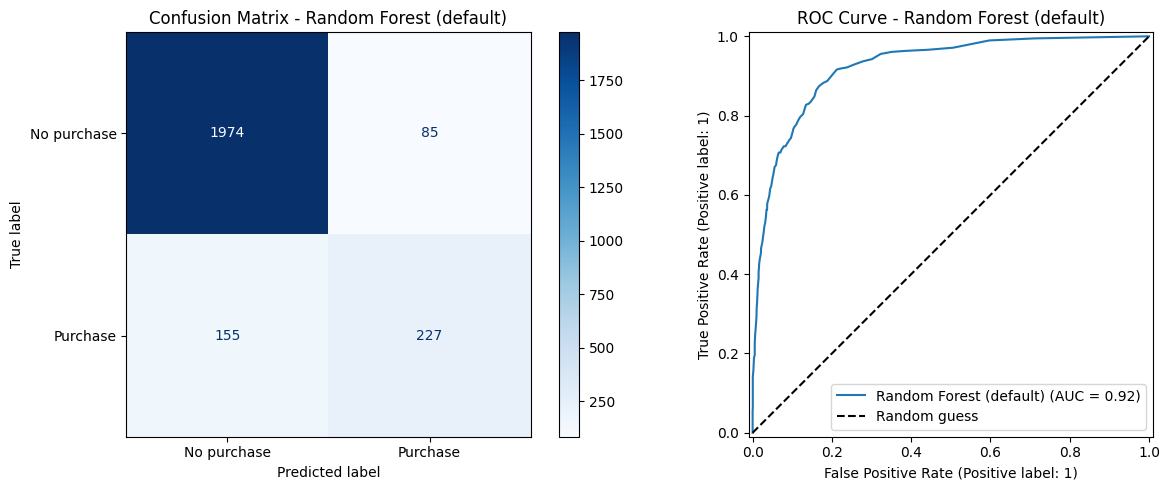

                  Model  Train acc  Test acc  Precision  Recall    F1  ROC-AUC
Random Forest (default)        1.0     0.902      0.728   0.594 0.654    0.924


In [20]:
# Random Forest with default settings
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf.fit(X_train_p, y_train)
results.append(evaluate("Random Forest (default)", rf))
print(pd.DataFrame(results).round(3).to_string(index=False))

### Interpretation: Random Forest (Default Settings)

I trained a Random Forest with its default settings: 100 fully grown trees, each trained on a random sample of the training sessions and using a random subset of about 6 features at each split. The final prediction is the majority vote of all 100 trees.

Overfitting:
Training accuracy is 100%, because each fully grown tree memorizes the sessions it was trained on. However, test accuracy is still 90.2%, because averaging the votes of 100 different trees cancels out many of their individual mistakes.

Confusion matrix (2,441 test sessions):
- 1,974 non-buyers and 227 buyers were classified correctly.
- 85 non-buyers were wrongly predicted as buyers (false positives).
- 155 buyers were missed (false negatives).

Classification report:
- Purchase class: precision 0.73, recall 0.59, F1 0.65. When the model predicts a purchase, it is right 73% of the time, but it only finds 59% of the real buyers.
- No purchase class: precision 0.93, recall 0.96.

ROC-AUC is 0.924, so the model ranks buyers above non-buyers very well.

Compared to the default logistic regression model from my previous assignment (accuracy 0.896, F1 0.639, ROC-AUC 0.921), the default Random Forest is slightly better on every metric. Like logistic regression, its main weakness is low recall for buyers, because the default settings do not account for the class imbalance.

## Step 6: Train and Evaluate an XGBoost Model

=== XGBoost (default) ===
              precision    recall  f1-score   support

 No purchase       0.93      0.95      0.94      2059
    Purchase       0.71      0.59      0.65       382

    accuracy                           0.90      2441
   macro avg       0.82      0.77      0.79      2441
weighted avg       0.89      0.90      0.89      2441



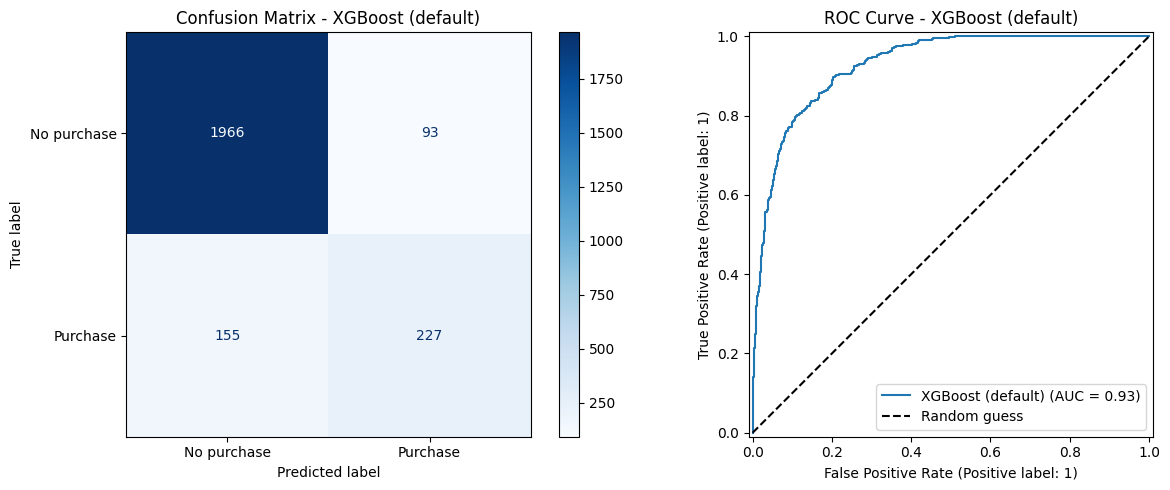

                  Model  Train acc  Test acc  Precision  Recall    F1  ROC-AUC
Random Forest (default)      1.000     0.902      0.728   0.594 0.654    0.924
      XGBoost (default)      0.982     0.898      0.709   0.594 0.647    0.929


In [21]:
xgb = XGBClassifier(random_state=42, n_jobs=-1, eval_metric="logloss")
xgb.fit(X_train_p, y_train)
results.append(evaluate("XGBoost (default)", xgb))
print(pd.DataFrame(results).round(3).to_string(index=False))

### Interpretation: XGBoost (Default Settings)

I trained XGBoost with its default settings: 100 trees built one after another, each with a maximum depth of 6, and a learning rate of 0.3. Each new tree focuses on correcting the mistakes of the trees before it.

Overfitting:
Training accuracy is 98.2%, lower than Random Forest's 100%, while test accuracy is 89.8%. XGBoost uses shallower trees and adds them step by step, so it memorizes the training data a little less.

Confusion matrix:
- 1,966 non-buyers and 227 buyers were classified correctly.
- 93 non-buyers were wrongly predicted as buyers (false positives).
- 155 buyers were missed (false negatives), exactly the same number as Random Forest.

Classification report:
- Purchase class: precision 0.71, recall 0.59, F1 0.65.
- No purchase class: precision 0.93, recall 0.95.

ROC-AUC is 0.929, the highest so far, so XGBoost is slightly better than Random Forest (0.924) at ranking buyers above non-buyers.

Compared to Random Forest, the default XGBoost has almost the same recall and F1 (0.647 vs 0.654) and slightly lower precision, but a higher ROC-AUC. The differences are very small (8 more false positives), so I cannot pick a clear winner from these default results alone.

In [22]:
## Step 7: Comparing Random Forest and XGBoost (Default Settings)

Test set results:
                  Model  Train acc  Test acc  Precision  Recall    F1  ROC-AUC
Random Forest (default)      1.000     0.902      0.728   0.594 0.654    0.924
      XGBoost (default)      0.982     0.898      0.709   0.594 0.647    0.929


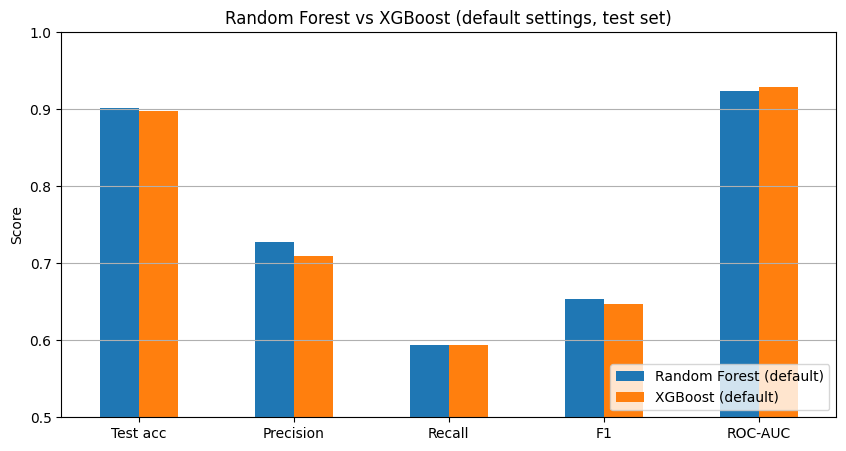


5-fold cross-validation (training data):
                  Model  accuracy  precision  recall    f1  f1 (std)  roc_auc
Random Forest (default)     0.901      0.748   0.557 0.638     0.014    0.924
      XGBoost (default)     0.894      0.691   0.584 0.633     0.017    0.919


In [23]:
# Test set comparison
compare_df = pd.DataFrame(results).round(3)
print("Test set results:")
print(compare_df.to_string(index=False))

compare_df.set_index("Model")[["Test acc", "Precision", "Recall", "F1", "ROC-AUC"]].T.plot(
    kind="bar", figsize=(10, 5), rot=0)
plt.ylim(0.5, 1.0); plt.ylabel("Score")
plt.title("Random Forest vs XGBoost (default settings, test set)")
plt.legend(loc="lower right"); plt.grid(axis="y"); plt.show()

# 5-fold cross-validation on the training data (more reliable than one test split)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = []
for name, model in [("Random Forest (default)", RandomForestClassifier(random_state=42, n_jobs=-1)),
                    ("XGBoost (default)", XGBClassifier(random_state=42, n_jobs=-1, eval_metric="logloss"))]:
    cv = cross_validate(model, X_train_p, y_train, cv=cv5, scoring=scoring)
    row = {"Model": name}
    for m in scoring:
        row[m] = round(cv[f"test_{m}"].mean(), 3)
        row[m + " (std)"] = round(cv[f"test_{m}"].std(), 3) if m == "f1" else None
    cv_rows.append({k: v for k, v in row.items() if v is not None})
print("\n5-fold cross-validation (training data):")
print(pd.DataFrame(cv_rows).to_string(index=False))

### Interpretation: Random Forest vs XGBoost (Default Settings)

On the test set, Random Forest is slightly ahead on accuracy (0.902 vs 0.898), precision (0.728 vs 0.709) and F1 (0.654 vs 0.647). XGBoost has a slightly higher ROC-AUC (0.929 vs 0.924). Both models have the same recall of 0.594, so each one still misses about 4 out of 10 buyers.

The 5-fold cross-validation on the training data gives the same picture:
- Random Forest: F1 0.638, precision 0.748, recall 0.557, ROC-AUC 0.924
- XGBoost: F1 0.633, precision 0.691, recall 0.584, ROC-AUC 0.919

The F1 difference between the two models is only 0.005. That is smaller than the variation between folds (std 0.014 to 0.017), so with default settings the two models are essentially tied. Random Forest is a bit more precise, while XGBoost catches a few more buyers.

Both default models have low recall because the data is imbalanced (only about 15% of sessions end in a purchase) and they use the default 0.5 threshold. Their F1 is about the same as my baseline Logistic Regression from Assignment 12 (0.639). Next I will tune both models and handle the class imbalance, to see which one improves more.

## Step 8: Hyperparameter Tuning – Random Forest

In [25]:
rf_params = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [None, "balanced", "balanced_subsample", {0: 1, 1: 3}]
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=rf_params,
    n_iter=30, scoring="f1", cv=cv5,
    random_state=42, n_jobs=-1, return_train_score=True
)
rf_search.fit(X_train_p, y_train)

print("Best parameters:", rf_search.best_params_)
print("Best CV F1:", round(rf_search.best_score_, 3))
best_i = rf_search.best_index_
print("Train F1 (CV):", round(rf_search.cv_results_["mean_train_score"][best_i], 3))

Best parameters: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 10, 'class_weight': {0: 1, 1: 3}}
Best CV F1: 0.686
Train F1 (CV): 0.79


In [26]:
# Top 5 combinations
top5 = pd.DataFrame(rf_search.cv_results_).sort_values("rank_test_score").head(5)
print(top5[["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
            "param_max_features", "param_class_weight",
            "mean_train_score", "mean_test_score", "std_test_score"]].round(3).to_string(index=False))

 param_n_estimators param_max_depth  param_min_samples_leaf param_max_features param_class_weight  mean_train_score  mean_test_score  std_test_score
                300              10                       5                0.5       {0: 1, 1: 3}             0.790            0.686           0.019
                300              20                       2               log2           balanced             0.920            0.686           0.014
                300              10                       1               log2       {0: 1, 1: 3}             0.759            0.685           0.018
                300              20                       2               sqrt           balanced             0.848            0.683           0.012
                300              20                       1               sqrt           balanced             0.889            0.681           0.014


=== Random Forest (tuned) ===
              precision    recall  f1-score   support

 No purchase       0.95      0.92      0.94      2059
    Purchase       0.65      0.75      0.69       382

    accuracy                           0.90      2441
   macro avg       0.80      0.84      0.82      2441
weighted avg       0.90      0.90      0.90      2441



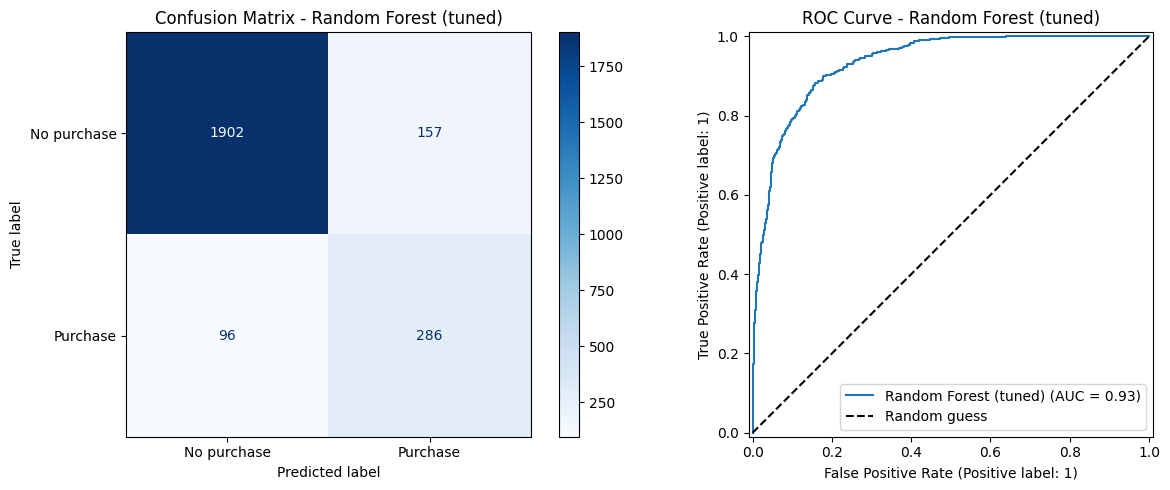

In [27]:
# Evaluate the best model on the test set
rf_best = rf_search.best_estimator_
results.append(evaluate("Random Forest (tuned)", rf_best))

### Interpretation: Tuned Random Forest

I tested 30 random combinations with 5-fold cross-validation and chose the best one by F1. The best settings were 300 trees, max_depth 10, min_samples_leaf 5, min_samples_split 10, max_features 0.5 and class_weight {0: 1, 1: 3}. Interestingly, this is the same class weight that worked best for Logistic Regression in Assignment 12.

Cross-validation:
The best CV F1 was 0.686, up from 0.638 for the default forest. The training F1 is 0.79, so the gap between train and CV is much smaller than with the default model, which memorized the training data at 100%. Limiting the depth to 10 and requiring at least 5 sessions per leaf reduced the overfitting. The top 5 combinations all scored between 0.681 and 0.686, so the model is not very sensitive to the exact settings once the class imbalance is handled.

Test set:
- Recall improved from 0.59 to 0.75: the model now catches 286 of 382 buyers and misses only 96 (before, it missed 155).
- Precision dropped from 0.73 to 0.65, because there are more false alarms (157 non-buyers predicted as buyers).
- F1 improved from 0.654 to 0.69, and ROC-AUC is 0.93.
- Accuracy stays at about 90%.

Compared with my tuned Logistic Regression from Assignment 12, the tuned Random Forest catches almost the same number of buyers (286 vs 287), with fewer false alarms (157 vs 174), so its F1 is slightly higher (0.69 vs 0.68).

## Step 9: Hyperparameter Tuning – XGBoost

In [28]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("Non-buyers per buyer (scale_pos_weight):", round(ratio, 2))

xgb_params = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4, 5, 6],
    "min_child_weight": [1, 3, 5, 10],
    "gamma": [0, 0.1, 0.5, 1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.7, 0.9, 1.0],
    "reg_lambda": [1, 3, 5, 10],
    "scale_pos_weight": [1, 3, ratio]
}

xgb_search = RandomizedSearchCV(
    XGBClassifier(random_state=42, n_jobs=1, eval_metric="logloss"),
    param_distributions=xgb_params,
    n_iter=40, scoring="f1", cv=cv5,
    random_state=42, n_jobs=-1, return_train_score=True
)
xgb_search.fit(X_train_p, y_train)

print("Best parameters:", xgb_search.best_params_)
print("Best CV F1:", round(xgb_search.best_score_, 3))
best_i = xgb_search.best_index_
print("Train F1 (CV):", round(xgb_search.cv_results_["mean_train_score"][best_i], 3))

Non-buyers per buyer (scale_pos_weight): 5.4
Best parameters: {'subsample': 0.8, 'scale_pos_weight': 3, 'reg_lambda': 5, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.05, 'gamma': 0.5, 'colsample_bytree': 1.0}
Best CV F1: 0.682
Train F1 (CV): 0.73


In [29]:
top5 = pd.DataFrame(xgb_search.cv_results_).sort_values("rank_test_score").head(5)
print(top5[["param_n_estimators", "param_learning_rate", "param_max_depth",
            "param_min_child_weight", "param_scale_pos_weight",
            "mean_train_score", "mean_test_score", "std_test_score"]].round(3).to_string(index=False))

 param_n_estimators  param_learning_rate  param_max_depth  param_min_child_weight  param_scale_pos_weight  mean_train_score  mean_test_score  std_test_score
                200                 0.05                4                      10                     3.0             0.730            0.682           0.012
                300                 0.01                6                       5                     3.0             0.737            0.681           0.016
                300                 0.01                4                       1                     3.0             0.694            0.680           0.017
                200                 0.01                4                       1                     3.0             0.700            0.680           0.017
                300                 0.20                2                       1                     3.0             0.712            0.679           0.022


=== XGBoost (tuned) ===
              precision    recall  f1-score   support

 No purchase       0.96      0.91      0.93      2059
    Purchase       0.62      0.78      0.69       382

    accuracy                           0.89      2441
   macro avg       0.79      0.85      0.81      2441
weighted avg       0.90      0.89      0.89      2441



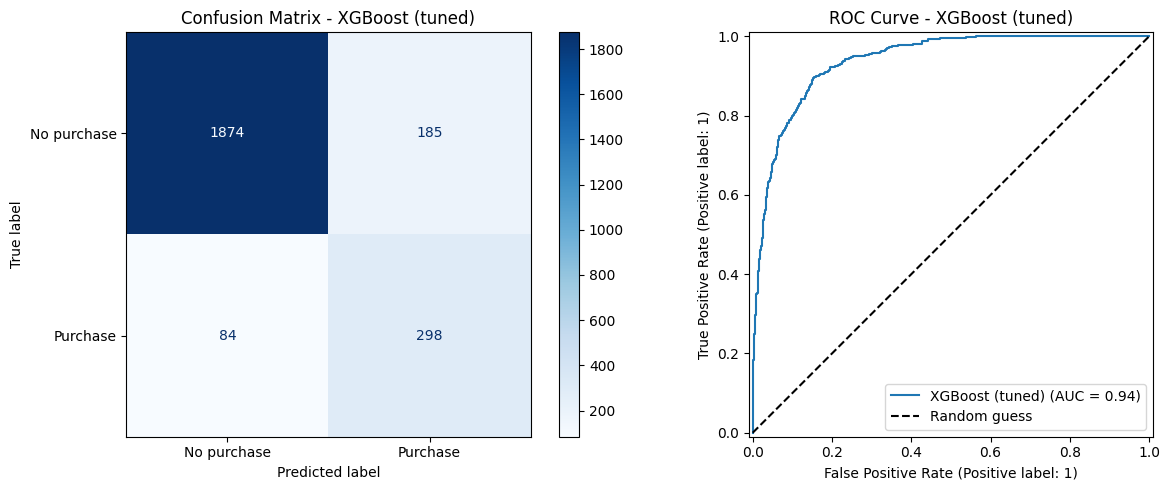

In [30]:
xgb_best = xgb_search.best_estimator_
results.append(evaluate("XGBoost (tuned)", xgb_best))

### Interpretation: Tuned XGBoost

I tested 40 random combinations with 5-fold cross-validation and chose the best one by F1. The best settings were 200 trees, learning_rate 0.05, max_depth 4, min_child_weight 10, gamma 0.5, subsample 0.8, colsample_bytree 1.0, reg_lambda 5 and scale_pos_weight 3. All top 5 combinations used scale_pos_weight 3. That means giving buyers 3 times more weight works better than no weighting (1) or full balancing (5.4), which matches what I found for Random Forest and Logistic Regression.

Cross-validation:
The best CV F1 was 0.682, up from 0.633 for the default XGBoost. The training F1 is 0.73, so the gap between train and CV is only about 0.05. That is half the gap of the tuned Random Forest (0.10). The shallow trees (depth 4), the small learning rate and the regularization (gamma, min_child_weight, reg_lambda) kept the model from overfitting.

Test set:
- Recall improved from 0.59 to 0.78: the model catches 298 of 382 buyers and misses only 84, the fewest of all models.
- Precision dropped to 0.62, with 185 false alarms.
- F1 improved from 0.647 to 0.69, and ROC-AUC is 0.94, the highest of all models.
- Accuracy is 89%.

Compared with the tuned Random Forest, XGBoost catches 12 more buyers but makes 28 more false alarms, so their F1 scores are almost identical (0.689 vs 0.693). XGBoost ranks buyers better (higher ROC-AUC) and overfits less, while Random Forest is slightly more precise.

## Step 10: Final Comparison – Random Forest vs XGBoost vs Logistic Regression

In [31]:
# All test results + tuned Logistic Regression from Assignment 12 (same split and preparation)
final_df = pd.DataFrame(results).round(3)
lr_row = {"Model": "Logistic Regression (tuned, A12)", "Train acc": np.nan, "Test acc": 0.890,
          "Precision": 0.623, "Recall": 0.751, "F1": 0.681, "ROC-AUC": 0.925}
final_df = pd.concat([final_df, pd.DataFrame([lr_row])], ignore_index=True)
print("Test set results:")
print(final_df.to_string(index=False))

Test set results:
                           Model  Train acc  Test acc  Precision  Recall    F1  ROC-AUC
         Random Forest (default)      1.000     0.902      0.728   0.594 0.654    0.924
               XGBoost (default)      0.982     0.898      0.709   0.594 0.647    0.929
           Random Forest (tuned)      0.925     0.896      0.646   0.749 0.693    0.934
                 XGBoost (tuned)      0.901     0.890      0.617   0.780 0.689    0.939
Logistic Regression (tuned, A12)        NaN     0.890      0.623   0.751 0.681    0.925


In [32]:
# Cross-validated F1 (training data)
cv_summary = pd.DataFrame({
    "Model": ["Random Forest (default)", "XGBoost (default)", "Random Forest (tuned)",
              "XGBoost (tuned)", "Logistic Regression (tuned, A12)"],
    "CV F1": [0.638, 0.633, round(rf_search.best_score_, 3), round(xgb_search.best_score_, 3), 0.673]
})
print("\n5-fold CV F1:")
print(cv_summary.to_string(index=False))



5-fold CV F1:
                           Model  CV F1
         Random Forest (default)  0.638
               XGBoost (default)  0.633
           Random Forest (tuned)  0.686
                 XGBoost (tuned)  0.682
Logistic Regression (tuned, A12)  0.673


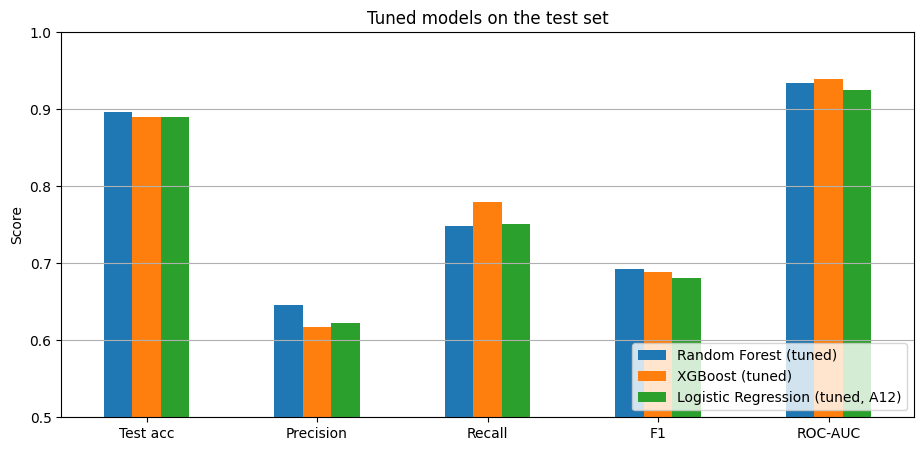

In [33]:
# Bar chart: tuned models only
tuned_df = final_df[final_df["Model"].str.contains("tuned")]
tuned_df.set_index("Model")[["Test acc", "Precision", "Recall", "F1", "ROC-AUC"]].T.plot(
    kind="bar", figsize=(11, 5), rot=0)
plt.ylim(0.5, 1.0); plt.ylabel("Score")
plt.title("Tuned models on the test set")
plt.legend(loc="lower right"); plt.grid(axis="y"); plt.show()

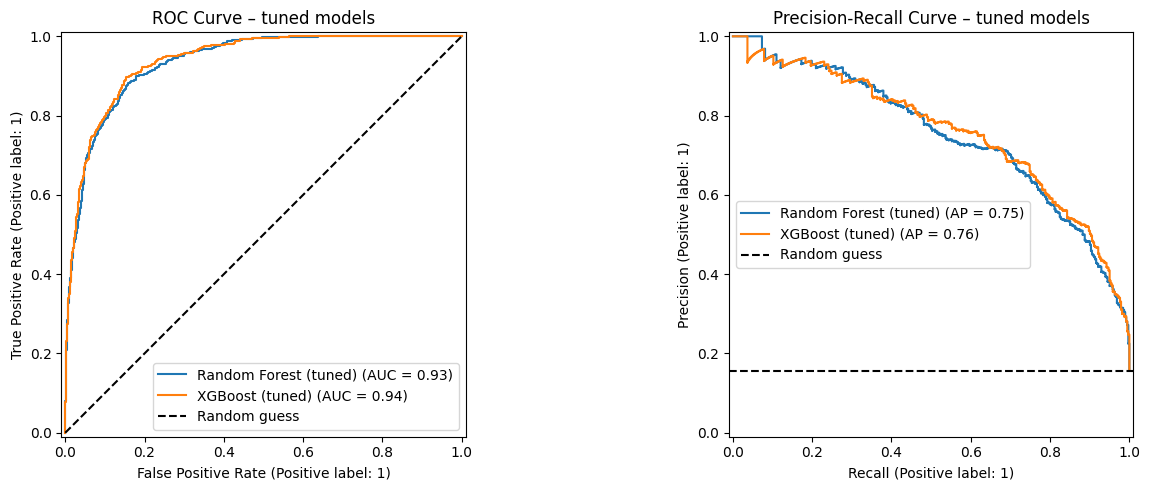

In [34]:
# ROC and Precision-Recall curves of both tuned models on one chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, model in [("Random Forest (tuned)", rf_best), ("XGBoost (tuned)", xgb_best)]:
    RocCurveDisplay.from_estimator(model, X_test_p, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(model, X_test_p, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess"); axes[0].legend()
axes[0].set_title("ROC Curve – tuned models")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Random guess")
axes[1].legend(); axes[1].set_title("Precision-Recall Curve – tuned models")
plt.tight_layout(); plt.show()

### Interpretation: Final Comparison of All Models

Effect of tuning:
Tuning improved both models a lot. Cross-validated F1 went from 0.638 to 0.686 for Random Forest and from 0.633 to 0.682 for XGBoost. On the test set, recall went from 0.59 to 0.75 (Random Forest) and 0.78 (XGBoost), so the models now catch about 3 out of 4 buyers instead of 3 out of 5. The biggest gain came from handling the class imbalance (class_weight and scale_pos_weight of 3). Precision dropped a bit as a trade-off. Tuning also reduced overfitting: Random Forest's training accuracy fell from 100% to 92.5%, and XGBoost's from 98.2% to 90.1%, while test performance improved.

Random Forest vs XGBoost:
The two tuned models are very close. Random Forest has a slightly higher F1 (0.693 vs 0.689 on test, 0.686 vs 0.682 in CV) and higher precision (0.646 vs 0.617). XGBoost has higher recall (0.780 vs 0.749), a higher ROC-AUC (0.939 vs 0.934) and a higher average precision (0.76 vs 0.75). Its gap between training and test accuracy is also smaller (0.011 vs 0.029). The F1 difference of 0.004 is smaller than the variation between CV folds (about 0.015), so on F1 alone they are tied. The ROC and Precision-Recall curves almost overlap, with XGBoost slightly above in the middle recall range.

Compared with Logistic Regression (Assignment 12):
Both tree models beat my tuned Logistic Regression on every main metric: F1 0.69 vs 0.68, ROC-AUC 0.93–0.94 vs 0.925. The biggest improvement is in average precision: 0.75–0.76 vs 0.68. This means the tree models keep higher precision as recall increases, probably because they can capture non-linear patterns and interactions (for example, PageValues combined with the month or the visitor type) that a linear model cannot.

## Step 11: Feature Importance – Random Forest vs XGBoost

In [35]:
# Random Forest: average impurity (Gini) decrease across all trees
rf_imp = pd.Series(rf_best.feature_importances_, index=X_train_p.columns)

In [36]:
# XGBoost: average gain (loss improvement) when a feature is used to split
gain = xgb_best.get_booster().get_score(importance_type="gain")
xgb_imp = pd.Series(gain).reindex(X_train_p.columns, fill_value=0)
xgb_imp = xgb_imp / xgb_imp.sum()    

In [37]:
# Top 10 side by side
imp_df = pd.DataFrame({"Random Forest": rf_imp, "XGBoost (gain)": xgb_imp}).round(3)
imp_df["RF rank"] = imp_df["Random Forest"].rank(ascending=False).astype(int)
imp_df["XGB rank"] = imp_df["XGBoost (gain)"].rank(ascending=False).astype(int)
print(imp_df.sort_values("Random Forest", ascending=False).head(10).to_string())

                         Random Forest  XGBoost (gain)  RF rank  XGB rank
PageValues                       0.621           0.406        1         1
ExitRates                        0.084           0.016        2        16
ProductRelated_Duration          0.069           0.022        3         8
ProductRelated                   0.049           0.016        4        16
Month_Nov                        0.041           0.085        5         2
Administrative_Duration          0.034           0.017        6        14
Administrative                   0.028           0.020        7        11
Informational_Duration           0.014           0.013        8        21
Month_May                        0.010           0.057        9         3
Informational                    0.007           0.014       10        20


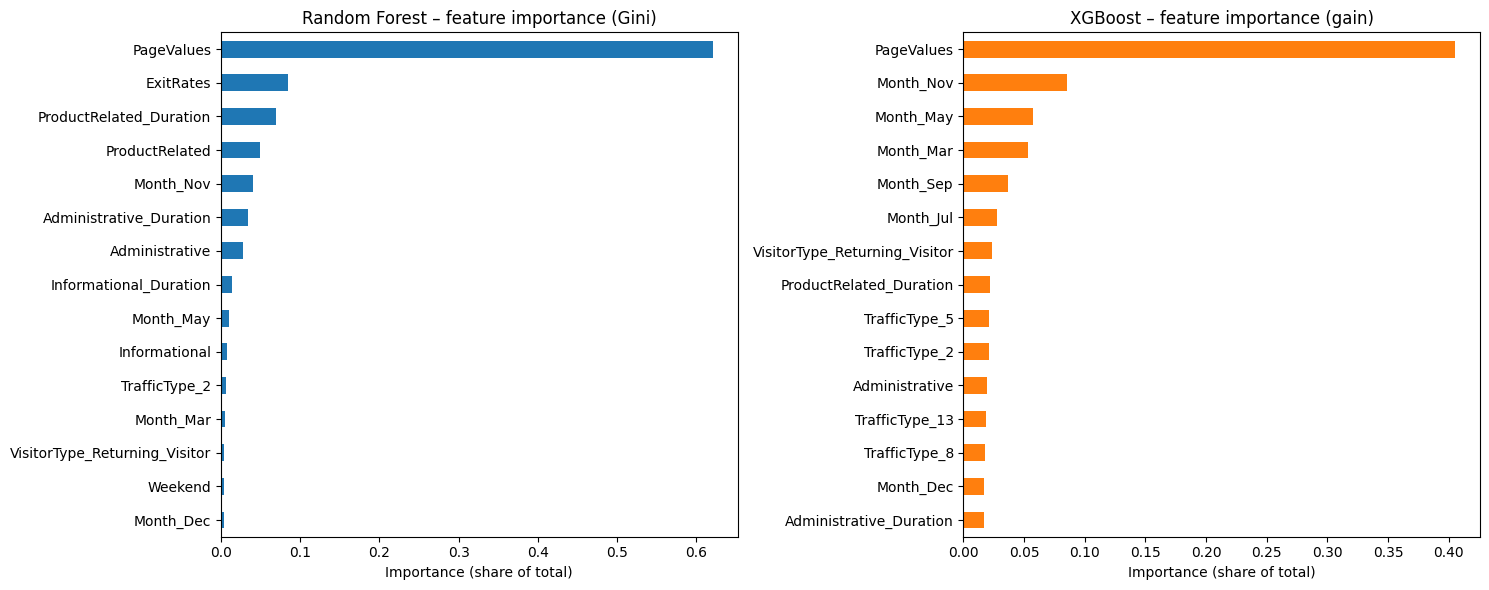

In [38]:
# Top 15 bar charts
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
rf_imp.sort_values().tail(15).plot(kind="barh", ax=axes[0], color="tab:blue")
axes[0].set_title("Random Forest – feature importance (Gini)")
xgb_imp.sort_values().tail(15).plot(kind="barh", ax=axes[1], color="tab:orange")
axes[1].set_title("XGBoost – feature importance (gain)")
for ax in axes: ax.set_xlabel("Importance (share of total)")
plt.tight_layout(); plt.show()

### Interpretation: Feature Importance

Both models rank PageValues as the most important feature by far: 62% of the total importance in Random Forest and 41% in XGBoost. This matches Assignment 12, where PageValues had the largest odds ratio (4.52) in Logistic Regression. When a visitor has already viewed pages that usually lead to a purchase, they are much more likely to buy.

After PageValues, the two models rank the features differently:
- Random Forest gives the next highest importance to browsing behaviour: ExitRates (0.084), ProductRelated_Duration (0.069), ProductRelated (0.049) and the Administrative features. Gini importance tends to favour continuous features because they offer many possible split points.
- XGBoost gives the next highest importance to the months: November (0.085), May (0.057), March, September and July, followed by Returning_Visitor and some traffic types. XGBoost's gain measures the average improvement per split, so a simple yes/no feature like "is it November?" scores high when it separates buyers well, even if it is used less often.

So both models agree that what the visitor did on the site (PageValues) matters most, and that the season matters next, especially November (the Black Friday / holiday shopping period). From a marketing point of view, this suggests focusing remarketing and ad budget on visitors who reach high-value pages, and increasing spend in November.

Because the model depends so heavily on PageValues, its performance depends on that feature being available at prediction time. In Assignment 12, removing PageValues dropped the F1 to 0.377.

## Step 12: Final Report – Random Forest vs XGBoost

### Dataset and approach
I used the Online Shoppers Purchasing Intention dataset (12,205 sessions after removing duplicates, about 15.6% buyers) instead of the Breast Cancer dataset. I used the same 80/20 stratified split and preparation as Assignment 12, so I could compare Random Forest and XGBoost with my tuned Logistic Regression. The goal was to predict whether a session ends in a purchase (Revenue). Because the classes are imbalanced, I used F1 as the main metric, along with recall, precision and ROC-AUC.

### Results summary

| Model | CV F1 | Test F1 | Precision | Recall | ROC-AUC | Train acc |
|---|---|---|---|---|---|---|
| Random Forest (default) | 0.638 | 0.654 | 0.728 | 0.594 | 0.924 | 1.000 |
| XGBoost (default) | 0.633 | 0.647 | 0.709 | 0.594 | 0.929 | 0.982 |
| Random Forest (tuned) | 0.686 | 0.693 | 0.646 | 0.749 | 0.934 | 0.925 |
| XGBoost (tuned) | 0.682 | 0.689 | 0.617 | 0.780 | 0.939 | 0.901 |
| Logistic Regression (tuned, A12) | 0.673 | 0.681 | 0.623 | 0.751 | 0.925 | – |

### 1. Overall performance
Both models performed well, with about 90% accuracy and a ROC-AUC above 0.92 even with default settings. However, the default models missed about 40% of buyers (recall 0.59), because they used a 0.5 threshold on imbalanced data. The default Random Forest also memorized the training data (100% training accuracy).

### 2. Comparison
With default settings, the two models were essentially tied (CV F1 0.638 vs 0.633). After tuning, they were still very close. Random Forest had a slightly higher F1 (0.693) and precision (0.646). XGBoost had higher recall (0.780, catching 298 of 382 buyers), the highest ROC-AUC (0.939), the highest average precision (0.76) and the smallest train-test gap. Both tree models beat Logistic Regression, especially on average precision (0.75–0.76 vs 0.68), because they can capture non-linear patterns. The feature importance results showed that PageValues was the most important feature for both models.

### 3. Effect of hyperparameter tuning
Tuning improved CV F1 by about 0.05 for both models and raised recall from 0.59 to 0.75–0.78. The most important change was handling the class imbalance: a class weight / scale_pos_weight of 3 worked best for both models (the same weight as in Assignment 12). Limiting tree complexity (max_depth 10 and min_samples_leaf 5 for Random Forest; max_depth 4, learning_rate 0.05, gamma and reg_lambda for XGBoost) reduced overfitting. The trade-off was lower precision, meaning more false alarms.

### 4. Recommendation
I recommend **XGBoost** for this problem. In e-commerce marketing, missing a likely buyer usually costs more than showing a remarketing ad to someone who won't buy. XGBoost catches the most buyers (recall 0.78) and ranks sessions best (highest ROC-AUC and AP), which is useful for prioritizing ad spend. It also generalizes better (smallest train-test gap). If false alarms were expensive (for example, giving discounts to every predicted buyer), I would choose Random Forest for its higher precision. It is also simpler to tune.

### Limitations and next steps
- Both models rely heavily on PageValues. Without it, performance drops sharply (F1 0.377 in Assignment 12).
- I used the default 0.5 threshold. Tuning the threshold with cross-validation could improve F1 further.
- SHAP values could explain individual predictions better than the global feature importance.